In [3]:
from __future__ import division 
import math as mth
import numpy as np
import matplotlib.pylab as plt 

from sympy import *
import pandas as pd
import os, subprocess
from sklearn.linear_model import LinearRegression, RANSACRegressor, Lasso
from sklearn.linear_model.ransac import _dynamic_max_trials


 #efarmogi exwterikoy eswterikou prosanatolismou gia paragwgi pinaka pim sintetagmenwn eikonas
def Upimage(P,c,X0,Y0,Z0,R):  
    Pimg=np.zeros(np.shape(P))
    for i in range (3):
        if i==0:
            Pimg[:,i]=-c*((P[:,0]-X0)*R[0,0]+(P[:,1]-Y0)*R[0,1]+(P[:,2]-Z0)*R[0,2]) / ((P[:,0]-X0)*R[2,0]+(P[:,1]-Y0)*R[2,1]+(P[:,2]-Z0)*R[2,2])
        elif i==1:
            Pimg[:,i]=-c*((P[:,0]-X0)*R[1,0]+(P[:,1]-Y0)*R[1,1]+(P[:,2]-Z0)*R[1,2]) /((P[:,0]-X0)*R[2,0]+(P[:,1]-Y0)*R[2,1]+(P[:,2]-Z0)*R[2,2])  
        else :
            Pimg[:,i]=-c
    return Pimg 

def R_wfk(w,f,k):
    
    #1 h glwssa python kanei praxeis gwniwn se rad, 
    #ara gia na ta metatrepsw se monada metrisis moirwn kai na doyleyw me ayti ti monada metrisis
    #ginontai ta parakatw!!
   # an w=3 moires kai f=4, k=2 prepei na graftei ws exis:
   # w=np.array(3*(np.pi/180))
    #f=np.array(4*(np.pi/180))
    #k=np.array(2*(np.pi/180))

   #px1: #sinw=np.sin(w) -> h w gwnia se rad 
   # px2. : x = np.sin(np.array((0., 30., 45., 60., 90.)) * np.pi / 180. ) -> metatropi apo moires ths gwnias w se rad     
   #px2 edw ayti xrisimopoieitai:
    sinw=np.sin(np.array((w)*np.pi/200))
    cosw=np.cos(np.array((w)*np.pi/200))
    
    sinf=np.sin(np.array((f)*np.pi/200))
    cosf=np.cos(np.array((f)*np.pi/200))
    
    
    sink=np.sin(np.array((k)*np.pi/200))
    cosk=np.cos(np.array((k)*np.pi/200))   
   
    R1w=np.array([[1,0,0],
                  [0,cosw,sinw],
                  [0,-sinw,cosw]])
 
    R2f=np.array([[cosf,0,-sinf],
                  [0,1,0],
                  [sinf,0,cosf]])
  
    R3k=np.array([[cosk,sink,0],
                  [-sink,cosk,0],
                  [0,0,1]])
    R=np.dot(R3k,R1w)
    R=np.dot(R,R2f)   
 
    return R


In [4]:
with open('C:\\Users\gd\\Desktop\\DIPLOMATIKI\\python askiseis diplwmatikis\\projects\\project_1_4G0R6724\\outfile_1o.csv') as f:
    x=np.loadtxt(f)
    
Plane=np.zeros((x.shape[0],3))
for i in range (3):
    Plane[:,i]=x[:,i]

linepar_im=np.array([0.015624999999999905, 0.0086421875])
X0=1013.2260
Y0=1015.2280
Z0=104.0000
O=np.array([[X0,Y0,Z0]])
c=0.024
R=R_wfk(-61.4238,122.3646,80.5447)



In [20]:
#     RANSAC !!!!!!!!!!!
def show_3d_line(xyz,thr):  
    #  pragmatopoihsh ransac algorithmou, diaxwrismos simeiwn se inliers- outliers kai 3D apeikonisi toys.
    from matplotlib import pyplot as plt
    from mpl_toolkits.mplot3d import Axes3D
    from skimage.measure import LineModelND, ransac
 

    # robustly fit line only using inlier data with RANSAC algorithm
    
    if xyz.shape[0]>=50:        
        model_robust, inliers = ransac(xyz, LineModelND, min_samples=3,
                               residual_threshold=thr, max_trials=xyz.shape[0]+1)
        outliers = inliers == False
        fig = plt.figure()
        ax = fig.add_subplot(111, projection='3d')
        ax.scatter(xyz[inliers][:, 0], xyz[inliers][:, 1], xyz[inliers][:, 2], c='b',
           marker='o', label='Inlier data')
        ax.scatter(xyz[outliers][:, 0], xyz[outliers][:, 1], xyz[outliers][:, 2], c='r',
           marker='o', label='Outlier data')
        ax.legend(loc='lower left')
        plt.show()
        
    else:
        inliers=None            
    
    return inliers
##########################################
   # Save inliers and outliers
def Epilegmeni_akmi_inliers(Plane,inliers_Pl):
    
    j=np.sum(inliers_Pl==True)
    print ('inliers:',j)
    inl_Pl=np.zeros((j,3))
    j=0
    for i in range (Plane.shape[0]) :
        if inliers_Pl[i]==True:
            # edw dimiourgountai o pinakas telikos twn inliers: i
            inl_Pl[j,:]=Plane[i,:]  #1: tis akmis poy anixneytike sto pim 
            j+=1
    return inl_Pl
            
def epilogi_se_outliers(Plane,inliers_Pl):    
## if check==False:
    j=np.sum(inliers_Pl==False)
    print ('outliers:', j)
    outliers=np.zeros((j,3))
    j=0
    for i in range (Plane.shape[0]) :
        if inliers_Pl[i]==False:
            # edw dimiourgountai o pinakas telikos twn newn inliers :
            outliers[j,:]=Plane[i,:]  #1:tis akmis poy anixneytike sto pim 
            j=j+1
    return outliers
#########################################################################################            


      # Ransac: is model valid check 
def is_model_valid(xyz,linepar_im): # is Model near the line requested or not?
    #  Run check to results, to prove that the selected line is the real one.
    thres=0.0045
    result=xyz # : is the selected line detected. 
    result_im=Upimage(result,c,X0,Y0,Z0,R)
    res_x,res_y,_=result_im.T
    # edw:  Anixneysi μεσω ελαχιστων τετρaγωνων της καλύτερης ευθειας, y=ax+b eyresi parametrwn a,b.  
    # edw : stin eikona result_im
    #line_par1=least_squares(result_im)
    # Bimata gia elegxo Dx, Dy diaforwn sintetagmenwn.
    #1. orismos pinakwn:
    x_ch=np.zeros(result_im.shape[0])
    y_ch=np.zeros(result_im.shape[0])
    Dx=np.zeros(result_im.shape[0])
    Dy=np.zeros(result_im.shape[0])
     #2. Eyresi diaforwn
    for i in range (result_im.shape[0]):
        y_ch[i]=linepar_im[0]*res_x[i]+ linepar_im[1]
        x_ch[i]=(1/linepar_im[0])*res_y[i]-(linepar_im[1]/linepar_im[0])
    for i in range (result_im.shape[0]):
        Dx[i]= abs(res_x[i]- x_ch[i])
        Dy[i]= abs(res_y[i]- y_ch[i])
    print ("Oi megistes diafores sintetagmenwn kata Dx kai Dy antistoixa einai:",Dx.max(), Dy.max())
    if Dx.max()<=thres and Dy.max()<=thres:
        belongsto_selected_line=True
    else:
        belongsto_selected_line=False
  #  Telos elegxou, ara aporipsi i oxi tis epilegmenis akmis.
    return belongsto_selected_line  


def model_True(loops_Ransac):  #if model is valid, True or False
    valid_model=False
    i=0
    while valid_model==False and i<2:
        inliers_Pl=show_3d_line(loops_Ransac,0.006)
        inl=Epilegmeni_akmi_inliers(loops_Ransac,inliers_Pl)
        valid_model=is_model_valid(inl,linepar_im)
        if valid_model==False:
            loops_Ransac=epilogi_se_outliers(loops_Ransac,inliers_Pl)
    if valid_model==True:
        outl=epilogi_se_outliers(loops_Ransac,inliers_Pl)
    return inl,outl
#############################################################

         #Periorismoi Epilexe grammi pio konta sto simeio liyis
def dist_point_to_point(inliers,O):
    x1,y1,z1=O.T
    _=inliers.shape[0]
    dist=np.zeros((_,3))
    for i in range (_):
        x2,y2,z2=inliers[i,:].T
        dist[i]=np.sqrt((y2-y1)**2+(x2-x1)**2+(z2-z1)**2)
    min_dist=np.max(dist)    # iparxei logiki gia to giati epilexthike i max anti i min. logw prooptikis tha peftei panta swsta aytos o periorismos enw to min exei lathi ! 
    return min_dist



    

def File_exportTo_CloudCompare(epilogi):   #export result to files and compare results on  CloudCompare.
    result=epilogi #periorismos sta plaisia tis eikonas
    df = pd.DataFrame(data=result.astype(float))
    df.to_csv('epilegmeni_akmi_result.csv', sep=' ', header=False, float_format='%.2f', index=False)
    
   # export to cloudcompare 
    filePath = "C:\\Users\\gd\\Desktop\\NAXOS\\Textured_Model\\naosDimitrasNaxosMelina_PointcCloud.obj" #sure thing
    filepath2='C:\\Users\\gd\\Desktop\\DIPLOMATIKI\\python askiseis diplwmatikis\\projects\\project_1_4G0R6724\\epilegmeni_akmi_result.csv' #change please
    subprocess.Popen(['C:\Program Files\CloudCompare\CloudCompare', filePath,filepath2 ])    


     
def ask_user():    # Rwta ti gnwmi tou xristi
    _=False
    while _==False:
        User= input("Is the selected edge the one inserted in the program? Answer only with <<y>> for yes and <<n>> for No ")
        User=User.lower()
        if User not in ('y', 'yes', 'n', 'no','nai','oxi'):
            User= input('The value you entered is not valid Try again.Answer only with <<y>> for yes and <<n>> for No. ')
        else:
            _=True  
    if User in ('y', 'yes'):
        User=True #brethike i akmi
    else:
        User=False  # 
        print ('Sinexeia elegxwn,  den brethike akomi i zitoumeni akmi')
        
    return User


In [6]:
# https://www.programcreek.com/python/example/75200/sklearn.linear_model.RANSACRegressor !!!!!!! epitelous brika is data valid
# https://github.com/pierreant/wine-ml-on-aws-lambda/blob/master/sklearn/linear_model/tests/test_ransac.py

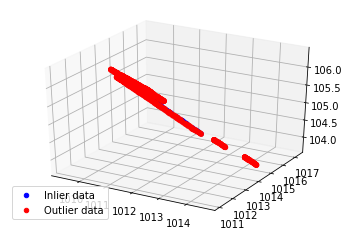

inliers: 201
Oi megistes diafores sintetagmenwn kata Dx kai Dy antistoixa einai: 0.04971185497675257 0.0007767477340117519
outliers: 1103


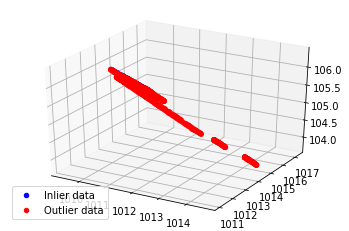

inliers: 124
Oi megistes diafores sintetagmenwn kata Dx kai Dy antistoixa einai: 0.002778578832299745 4.341529425468116e-05
outliers: 979


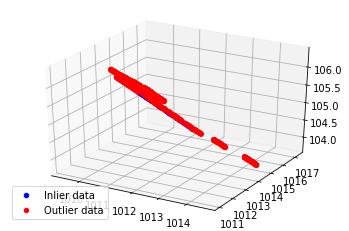

inliers: 88
Oi megistes diafores sintetagmenwn kata Dx kai Dy antistoixa einai: 0.08899694989829343 0.0013905773421608314
outliers: 891


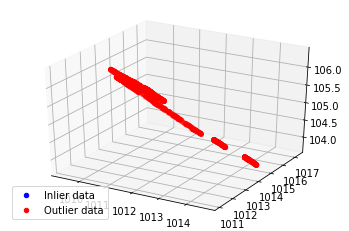

inliers: 72
Oi megistes diafores sintetagmenwn kata Dx kai Dy antistoixa einai: 0.0031573268084111377 4.933323138142133e-05
outliers: 819
Is the selected edge the one inserted in the program? Answer only with <<y>> for yes and <<n>> for No y
True


In [29]:
loops_Ransac=Plane
check=False
i=0
while check==False :
    # or while check==False or null inliers_Pl (skepsou ksana poy tha mpei to while)
    # pinakes inliers and outliers of each loop
    if i<=1:
#1st loop    
        inliers1,loops_Ransac=model_True(loops_Ransac)
        # outliers are considered the next input of the ransac-loop !
        dist1=dist_point_to_point(inliers1,O)
        i=1
#2nd and all the rest loops:       
    inliers2,loops_Ransac=model_True(loops_Ransac)
    # outliers are considered the next input of the ransac-loop !
    dist2=dist_point_to_point(inliers2,O)
    i+=1
    
    if dist1>dist2 :
        epilogi=inliers2
        # DEIXE TIN  STON XRISTI KAI RWTA TON AN  AYTI  EINAI I SWSTI AKMI. check= True or False gia sinexeia-i mi- tou loop
        _=File_exportTo_CloudCompare(epilogi)
        check=ask_user()      #epistrefei timi true false
        print (check)
        if check==False:
            epilogi=inliers1
            # DEIXE TIN  STON XRISTI KAI RWTA TON AN  AYTI  EINAI I SWSTI AKMI. check= True or False gia sinexeia-i mi- tou loop
            _=File_exportTo_CloudCompare(epilogi)
            check=ask_user()  #epistrefei timi true false
    elif dist1<dist2 :
        epilogi=inliers1
        # DEIXE TIN  STON XRISTI KAI RWTA TON AN  AYTI  EINAI I SWSTI AKMI. check= True or False gia sinexeia-i mi- tou loop
        _=File_exportTo_CloudCompare(epilogi)
        check=ask_user()      #epistrefei timi true false
        if check==False:
            epilogi=inliers2
            # DEIXE TIN  STON XRISTI KAI RWTA TON AN  AYTI  EINAI I SWSTI AKMI. check= True or False gia sinexeia-i mi- tou loop
            _=File_exportTo_CloudCompare(epilogi)
            check=ask_user()   #epistrefei timi true false     
    else:
        while True:
            print ('Choose the edge that was selected on the original photo. Is it A edge, B edge, or C not one of them is the right one? ')
            data = input("Pick an answer from A to C as explained:")
            if data.lower() not in ('a', 'b', 'c'):
                print("Not an appropriate choice.")  # EMFANISE KAI TIS 2 KAI BALE TO XRISTI NA DIALEKSEI
            else:
                break
        if data.lower() in ('a', 'b'):
            check=True
        else:
            check=False
                
    if check==False:
        if dist1>dist2 :
            inliers1=inliers2
            dist1=dist2
            


In [28]:
def FindIf_belongsto_photo(epilogi):
    # elegxos an i epilegmeni akmi einai mesa sta oria tis eikonas frame eikonas (0.036x0.024 m).
    FindIf_belongsto_photo=np.full((epilogi.shape[0]), False, dtype=bool)
    result_im=Upimage(epilogi,c,X0,Y0,Z0,R)
    for i in range (result_im.shape[0]):
        if ((-0.018<=result_im[i,0] and result_im[i,0]<=0.018) and (-0.012<=result_im[i,1] and result_im[i,1]<=0.012)):
            FindIf_belongsto_photo[i]=True
    j=np.sum(FindIf_belongsto_photo==True)
    result=np.zeros((j,3))
    j=0
    for i in range (result_im.shape[0]):
        if FindIf_belongsto_photo[i]==True:
            result[j,:]=epilogi[i,:]
            j+=1
    return result


if check==True:
    result=FindIf_belongsto_photo(epilogi)
    _=File_exportTo_CloudCompare(result)    


In [ ]:
loops_Ransac=Plane
inliers_Pl=show_3d_line(loops_Ransac,0.008)
inl=Epilegmeni_akmi_inliers(loops_Ransac,inliers_Pl)
outl=epilogi_se_outliers(loops_Ransac,inliers_Pl)



In [ ]:
loops_Ransac=Plane
check=False
while check==False or inliers_Pl!=None:
    # or while check==False or null inliers_Pl (skepsou ksana poy tha mpei to while)
    # pinakes inliers and outliers of each loop
#1st loop    
    inliers_Pl=show_3d_line(loops_Ransac,0.006,linepar_im)
    inliers1=Epilegmeni_akmi_inliers(loops_Ransac,inliers_Pl)
    loops_Ransac=epilogi_se_outliers(loops_Ransac,inliers_Pl) # outliers are considered the next input of the ransac-loop !
    dist1=dist_point_to_point(inliers1,O)
#2nd loop        
    inliers_Pl=show_3d_line(loops_Ransac,0.006,linepar_im)   
    inliers2=Epilegmeni_akmi_inliers(loops_Ransac,inliers_Pl)
    loops_Ransac=epilogi_se_outliers(loops_Ransac,inliers_Pl)
    dist2=dist_point_to_point(inliers2,O)
    if dist1>dist2 :
        epilogi=inliers2
        # DEIXE TIN  STON XRISTI KAI RWTA TON AN  AYTI  EINAI I SWSTI AKMI. check= True or False gia sinexeia-i mi- tou loop
        check=ask_user()
        if check==False:
            epilogi=inliers1
            # DEIXE TIN  STON XRISTI KAI RWTA TON AN  AYTI  EINAI I SWSTI AKMI. check= True or False gia sinexeia-i mi- tou loop
            check=ask_user()      
    elif dist1<dist2 :
        epilogi=inliers1
        # DEIXE TIN  STON XRISTI KAI RWTA TON AN  AYTI  EINAI I SWSTI AKMI. check= True or False gia sinexeia-i mi- tou loop
        check=ask_user()
        if check==False:
            epilogi=inliers2
            # DEIXE TIN  STON XRISTI KAI RWTA TON AN  AYTI  EINAI I SWSTI AKMI. check= True or False gia sinexeia-i mi- tou loop
            check=ask_user()     
    else:
        while True:
            print ('Choose the edge that was selected on the original photo. Is it A edge, B edge, or C not one of them is the right one? ')
            data = input("Pick an answer from A to C as explained:")
            if data.lower() not in ('a', 'b', 'c'):
                print("Not an appropriate choice.")  # EMFANISE KAI TIS 2 KAI BALE TO XRISTI NA DIALEKSEI
            else:
                break
        
        if data.lower() in ('a', 'b'):
            check=True
        else:
            check=False
                
    
        loops_Ransac
    

In [ ]:
RANSACRegressor (
base_estimator: NoneType=None,
min_samples: NoneType=None,
residual_threshold: NoneType=None,
is_data_valid: NoneType=None,
is_model_valid: NoneType=None,
max_trials: int=100,
max_skips: float=+Inf,
stop_n_inliers: float=+Inf,
stop_score: float=+Inf,
stop_probability: float=0.99,
loss: str=builtins.str,
random_state: NoneType=None
    
#(is_model_valid : callable, optional
#This function is called with the estimated model and the randomly selected data: is_model_valid(model, X, y).
#If its return value is False the current randomly chosen sub-sample is skipped.
#Rejecting samples with this function is computationally costlier than with is_data_valid. 
#is_model_valid should therefore only be used if the estimated model is needed for making the rejection decision.)

In [ ]:
ll=True
piii=np.array([[3,2,4],[4,8,4],[4,8,10]])
x=show_3d_line(piii,0.6,ll)
print (x)

In [ ]:
print (x)

In [ ]:
if check==False:
    print (np.sum(inliers_Pl==False))
    j=np.sum(inliers_Pl==False)
    outliers=np.zeros((j,3))
    j=0
    for i in range (inliers_Pl.shape[0]) :
        if inliers_Pl[i]==False:
            # edw dimiourgountai o pinakas telikos twn inliers:
            outliers[j,:]=Plane[i,:]  #1:tis akmis poy anixneytike sto pim 
            j+=1
            
    final=show_3d_line(outliers,0.014)
    print (np.sum(final==True))
    j=np.sum(final==True)
    inliers=np.zeros((j,3))
    j=0
    for i in range (final.shape[0]) :
        if final[i]==True:
            # edw dimiourgountai o pinakas telikos twn inliers:
            inliers[j,:]=outliers[i,:]  #1:tis akmis poy anixneytike sto pim 
            j+=1

